# 01 · Context and data
**Scenario (fictional):** a Category III U.S. bank holds a consumer portfolio of four products (credit card, auto, personal loan, HELOC). Its CECL lifetime-PD model went into production on development data (loans originated Jan 2022 to Jun 2023). Twelve months later, the quarterly monitoring pack shows defaults running above expectation. The task: decide whether the model needs a **Model Update**, scope it, do it, validate it, and document it.

All data are **synthetic**. This notebook introduces the portfolio and audits the raw extract before anything is modelled.

In [1]:
import sys; sys.path.insert(0, "../src")
from mu_catiii import *
from plots import *
pd.set_option("display.width", 160)
dev, mon, pd_old, lgd, ead = load_inputs()
pooled = pd.concat([dev, mon], ignore_index=True)
term_by_segment = pooled.groupby("segment")["term_months"].max().to_dict()

## 1. The portfolio
Two extracts with the same 28 columns: development (20,000 loans) and monitoring (10,000 loans, out of time).

In [2]:
display(pd.read_csv(RAW / 'development_raw.csv').head(3).T.head(28))

,0,1,2
loan_id,L10000000,L10000001,L10000002
segment,auto_loan,auto_loan,credit_card
origination_date,2022-10-03,2022-12-22,2022-08-07
funded_amount,"30,067.1800","31,680.8500","2,820.8200"
term_months,60,60,24
interest_rate,12.8810,9.5230,19.5360
fico_origination,745.0000,701.0000,698.0000
fico_current,730.0000,713.0000,686.0000
dti_ratio,37.7300,30.8400,25.1400
annual_income,"54,315.8500",NaN,"25,425.9400"


In [3]:
s = pd.read_csv(TABLES / '01_portfolio_summary.csv'); s['funded_usd_m'] = s.funded_usd / 1e6; s.drop(columns='funded_usd')

,period,segment,loans,default_rate,avg_fico,term_months,max_months_on_book,funded_usd_m
0,development,auto_loan,5969,0.0724,701.0895,60,35,148.4329
1,development,credit_card,5985,0.0707,699.0906,36,35,42.6335
2,development,heloc,3001,0.0810,699.5668,120,35,178.6643
3,development,personal_loan,5045,0.0725,699.9986,36,35,60.9005
4,monitoring,auto_loan,3070,0.0912,699.4332,60,29,76.2645
5,monitoring,credit_card,2906,0.0929,699.0712,36,29,20.5825
6,monitoring,heloc,1489,0.0920,701.1921,120,29,89.5491
7,monitoring,personal_loan,2535,0.0892,700.1675,36,29,30.6617


Development funded amount: $430,631,113  |  default rate 7.32%
Monitoring  funded amount: $217,057,726  |  default rate 9.13%

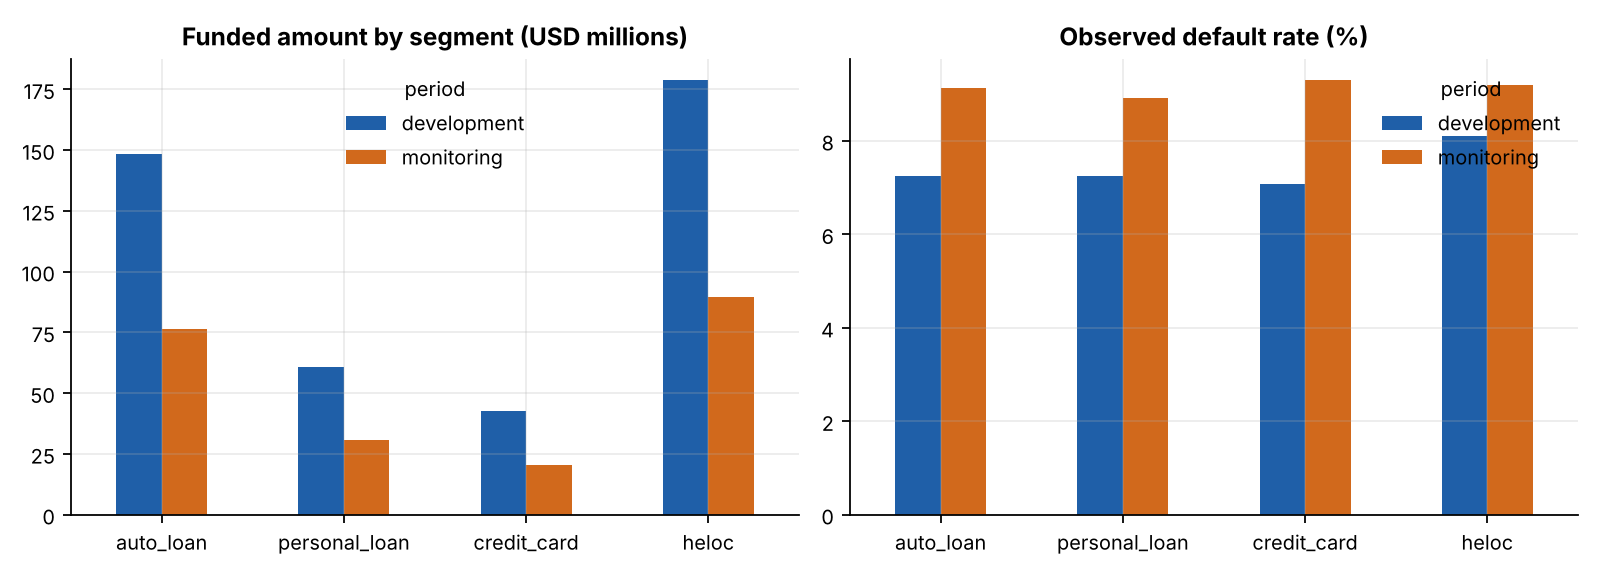

In [4]:
print(f"Development funded amount: ${dev.funded_amount.sum():,.0f}  |  default rate {dev.default_flag.mean():.2%}")
print(f"Monitoring  funded amount: ${mon.funded_amount.sum():,.0f}  |  default rate {mon.default_flag.mean():.2%}")
show_image(FIGS / 'fig01_portfolio_mix_and_default_rate.png')

## 2. Raw-data audit
The extracts are raw on purpose. Each problem below was found, treated, **flagged** in the processed file and not silently overwritten (the `*_raw` and `*_flag` columns stay in `data/processed`). The treatment is a documented assumption, see `docs/assumptions_and_limitations.md`.

In [5]:
pd.read_csv(TABLES / '01_raw_data_audit.csv')

,issue,development,monitoring,treatment
0,FICO at origination outside 300-850 (999),20,10,"set to missing, flagged, imputed (flag columns kept)"
1,Negative DTI,20,10,"set to missing, flagged, imputed"
2,Missing annual income,800,400,"imputed, `annual_income_imputed_flag`=1"
3,Missing DTI,399,200,"imputed, `dti_ratio_imputed_flag`=1"
4,Missing refreshed FICO,600,300,"fallback to origination FICO, `fico_current_source`"
5,Employment length missing/free text,600,300,parsed to years; unknown flagged
6,"Utilization empty (term loans, not applicable)",11014,5605,kept empty; `utilization_applicable_flag`=0 (NOT zero)
7,Duplicate loan_id,0,0,none found


Two points worth stating. First, utilization is empty for term loans because it does **not apply**, not because it is zero; a real 0% on a revolving line is a different fact. Second, `state` and `zip_code` are never model inputs: they are fair-lending review variables because geography can act as a proxy for protected classes.

## 3. Pools
CECL requires pooling loans with similar risk characteristics (ASC 326-20-30-2; characteristics listed in 55-5). Here: 4 segments × 4 FICO bands = 16 pools.

In [6]:
pc = pd.read_csv(TABLES / '01_pool_counts.csv'); pc['mon_share_of_pool'] = pc.monitoring / (pc.development + pc.monitoring); pc

,pool_id,development,monitoring,mon_share_of_pool
0,auto_loan | near-prime(640-679),1298,693,0.3481
1,auto_loan | prime(680-719),1713,871,0.3371
2,auto_loan | subprime(<640),780,421,0.3505
3,auto_loan | super-prime(720+),2178,1085,0.3325
4,credit_card | near-prime(640-679),1337,652,0.3278
5,credit_card | prime(680-719),1688,810,0.3243
6,credit_card | subprime(<640),816,403,0.3306
7,credit_card | super-prime(720+),2144,1041,0.3268
8,heloc | near-prime(640-679),649,302,0.3176
9,heloc | prime(680-719),835,436,0.3430


## 4. What changed between the two periods
The default rate rose and the macro inputs moved: unemployment up, house-price growth down. The mix of FICO bands did **not** move, so the pools are populated the same way; what changed is how they behave.

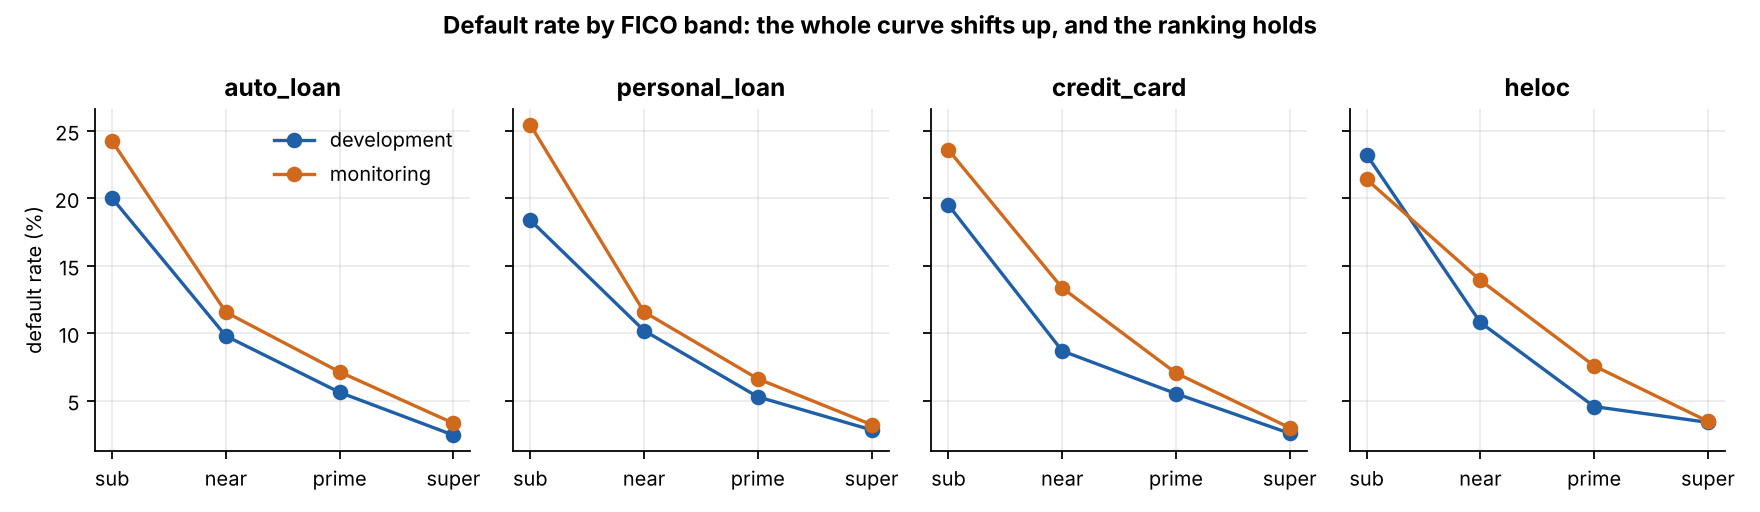

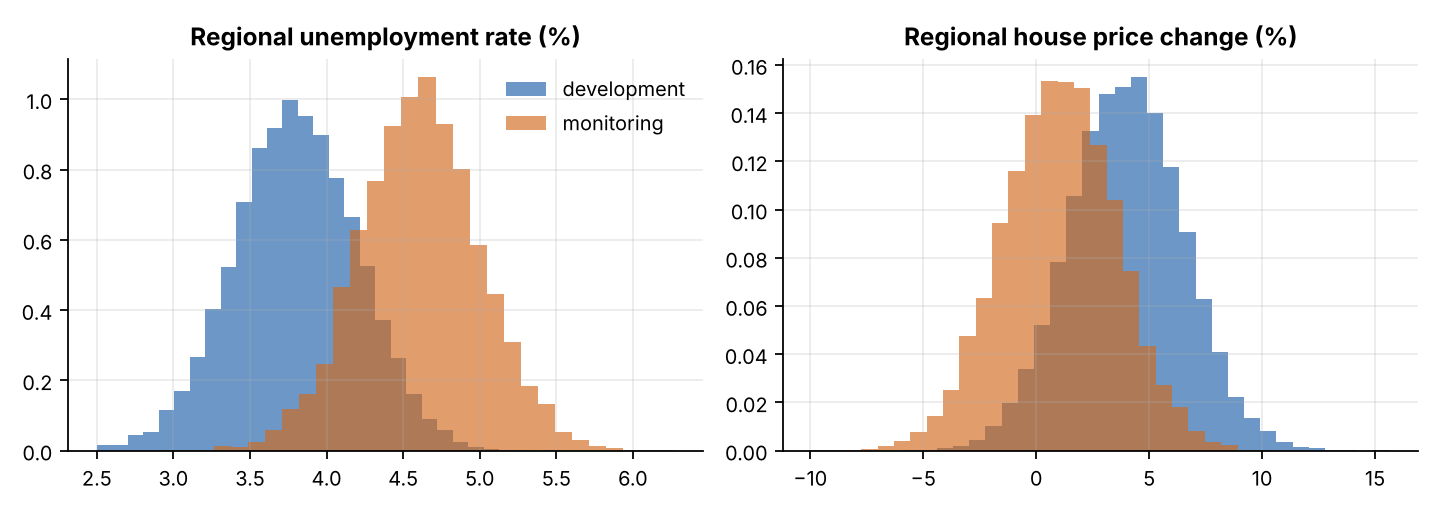

In [7]:
show_image(FIGS / 'fig02_default_by_fico_band.png'); show_image(FIGS / 'fig03_macro_drift.png')

In [8]:
print(dev[['unemployment_rate_regional','hpi_change_regional_pct']].mean().round(2).to_dict())
print(mon[['unemployment_rate_regional','hpi_change_regional_pct']].mean().round(2).to_dict())

{'unemployment_rate_regional': 3.8, 'hpi_change_regional_pct': 4.0}
{'unemployment_rate_regional': 4.6, 'hpi_change_regional_pct': 1.02}